<a href="https://colab.research.google.com/github/marinazakimi/ECAA08--Grupo-06/blob/main/etapa-03-arvores/%2023_Protocolo_de_Arvore_Geradora_STP_RSTP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 23 — Protocolo de Árvore Geradora — STP / RSTP

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

A estação de solo pode possuir servidor SCADA, HMI e gateway de rádio conectados por uma LAN Ethernet redundante. Esta é uma ampliação didática da arquitetura inicial: três switches e enlaces ponto a ponto. O STP evita loops de camada 2 bloqueando portas redundantes; o RSTP acrescenta mecanismos de convergência rápida.

O enlace sem fio entre drone e gateway é representado separadamente como disponibilidade de telemetria. Não afirmamos que STP roteia o drone, otimiza a missão aérea ou resolve a perda do rádio. As tags dos switches são novas e identificadas como equipamentos da estação de solo.

## 2. Modelo e fundamentação

O bridge raiz é o de menor Bridge ID (prioridade e identificador). Cada bridge não raiz escolhe uma root port pelo menor custo até a raiz, com desempates determinísticos. Em cada enlace, o anúncio superior determina a designated port. Uma porta alternativa fica em discarding no modelo RSTP. A topologia de encaminhamento estável é acíclica.

A seleção implementada é centralizada e calcula o resultado estável de uma LAN simples, com custos simétricos, sem enlaces paralelos e sem VLANs. Não é uma pilha de BPDUs. Os papéis são calculados por custo de caminho e IDs dos bridges/portas. Uma partição é informada, sem inventar comunicação entre componentes.

STP não minimiza a soma global dos enlaces. No exemplo, os custos SCADA–HMI e SCADA–RÁDIO são 10, enquanto HMI–RÁDIO custa 1. A árvore enraizada custa 20; uma AGM custa 11. A linha do tempo STP usa listening, learning e forwarding; a RSTP usa proposta, sincronização e acordo. Os tempos escolhidos são parâmetros ilustrativos, não medições.

## 3. Procedimento e demonstração

1. Eleger `SW_SCADA` como raiz pela prioridade configurada.
2. Exibir todas as portas, papéis e estados estáveis.
3. Comparar o resultado com Kruskal para mostrar que STP e AGM têm objetivos distintos.
4. Retirar o enlace SCADA–RÁDIO e calcular a nova topologia.
5. Comparar linhas do tempo didáticas de STP e RSTP e discutir perda de telemetria durante reconvergência.

Pergunta para a apresentação: recuperar a LAN comprova que o rádio do drone está funcionando? Não. São trechos diferentes da comunicação.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [ ]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [ ]:
def spanning_tree(links=LINKS):
    """Seleção centralizada dos papéis estáveis de STP, para LAN ponto a ponto.

    Custos simétricos; sem enlaces paralelos. Não emula troca completa de BPDUs.
    """
    validar_grafo(list(BRIDGES), links)
    if any(w <= 0 for _, _, w in links): raise ValueError('Custo de porta deve ser positivo')
    raiz = min(BRIDGES, key=BRIDGES.get)
    adj = {b: [] for b in BRIDGES}; portas = {}
    for i, (u, v, w) in enumerate(links, 1):
        adj[u].append((v, w, i)); adj[v].append((u, w, i))
        portas[(u, v)] = i; portas[(v, u)] = i
    dist = dict.fromkeys(BRIDGES, math.inf); dist[raiz] = 0; fila = [(0, raiz)]
    while fila:
        d, u = heapq.heappop(fila)
        if d != dist[u]: continue
        for v, w, _ in adj[u]:
            if d+w < dist[v]: dist[v] = d+w; heapq.heappush(fila, (d+w, v))
    if any(math.isinf(d) for d in dist.values()):
        return dict(raiz=raiz, status='PARTICIONADA', custo_raiz=dist, portas=[], ativas=[])
    pais = {}
    for v in BRIDGES:
        if v == raiz: continue
        _, _, _, _, vizinho = min((dist[u]+w, BRIDGES[u], portas[(u, v)], portas[(v, u)], u)
                                  for u, w, _ in adj[v])
        pais[v] = vizinho
    papeis = []; ativas = []
    for u, v, w in links:
        designado = min((u, v), key=lambda b: (dist[b], BRIDGES[b], portas[(b, v if b == u else u)]))
        roles = []
        for a, b in [(u, v), (v, u)]:
            papel = 'ROOT' if pais.get(a) == b else ('DESIGNATED' if a == designado else 'ALTERNATE')
            estado = 'DISCARDING' if papel == 'ALTERNATE' else 'FORWARDING'
            papeis.append((a, b, papel, estado)); roles.append(papel)
        if 'ALTERNATE' not in roles: ativas.append((u, v, w))
    return dict(raiz=raiz, status='CONECTADA', custo_raiz=dist, portas=papeis, ativas=ativas)


In [ ]:
def convergencia(protocolo, forward_delay=15.0, atraso_mensagem=.02):
    """Linha do tempo didática após detecção imediata; não é medição de equipamento."""
    if protocolo == 'STP':
        return [(0., 'LISTENING'), (forward_delay, 'LEARNING'), (2*forward_delay, 'FORWARDING')]
    if protocolo == 'RSTP':
        return [(0., 'DISCARDING / PROPOSAL'), (atraso_mensagem, 'SYNC / AGREEMENT'),
                (2*atraso_mensagem, 'FORWARDING')]
    raise ValueError('Protocolo desconhecido')


### Eleição, papéis e falha de enlace

Root bridge: SW_SCADA
('SW_SCADA', 'SW_HMI', 'DESIGNATED', 'FORWARDING')
('SW_HMI', 'SW_SCADA', 'ROOT', 'FORWARDING')
('SW_SCADA', 'SW_RADIO', 'DESIGNATED', 'FORWARDING')
('SW_RADIO', 'SW_SCADA', 'ROOT', 'FORWARDING')
('SW_HMI', 'SW_RADIO', 'DESIGNATED', 'FORWARDING')
('SW_RADIO', 'SW_HMI', 'ALTERNATE', 'DISCARDING')
Custo STP: 20 | custo AGM: 11
Após falha: [('SW_SCADA', 'SW_HMI', 10), ('SW_HMI', 'SW_RADIO', 1)]


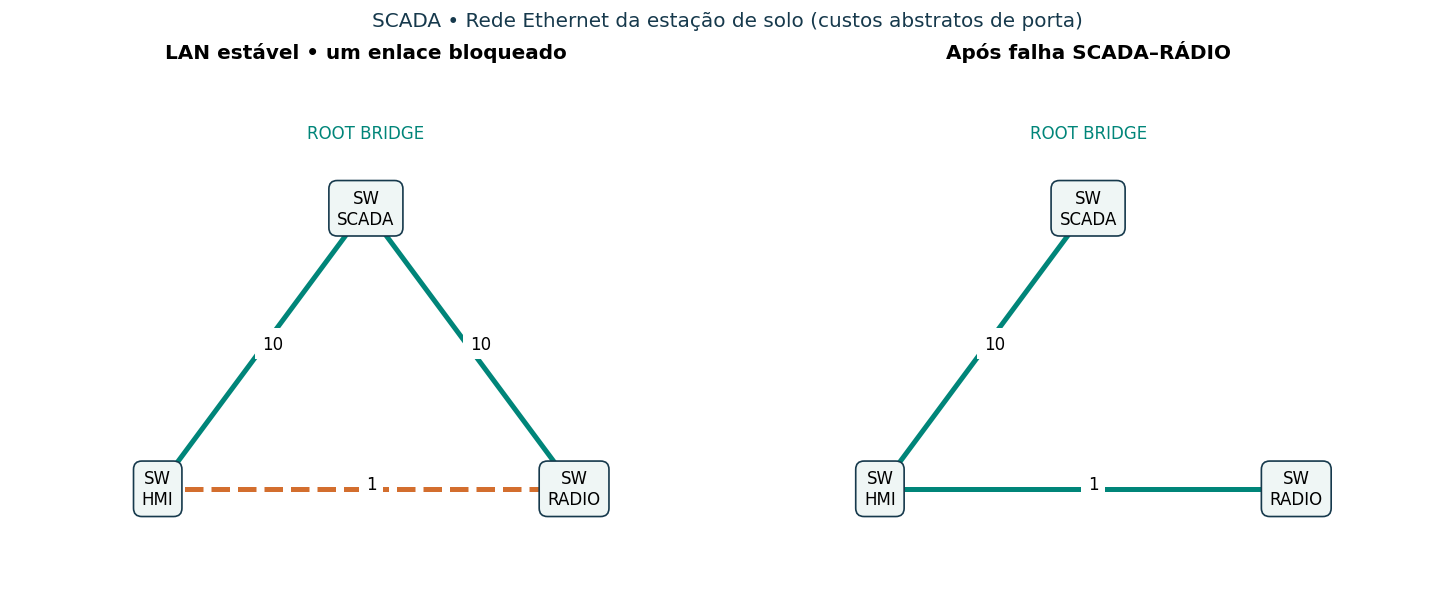

In [ ]:
rede=spanning_tree()
print('Root bridge:',rede['raiz'])
for porta in rede['portas']:print(porta)
agm,_=kruskal(list(BRIDGES),LINKS)
print('Custo STP:',custo(rede['ativas']),'| custo AGM:',custo(agm))
falha=spanning_tree([e for e in LINKS if set(e[:2])!={'SW_SCADA','SW_RADIO'}])
print('Após falha:',falha['ativas'])
vis.figura23();plt.show()

### Estados e temporização assumida

In [ ]:
for protocolo in ['STP','RSTP']:
    print(protocolo,convergencia(protocolo))
print('Observação: tempos de modelo, sem medição em switches.')

STP [(0.0, 'LISTENING'), (15.0, 'LEARNING'), (30.0, 'FORWARDING')]
RSTP [(0.0, 'DISCARDING / PROPOSAL'), (0.02, 'SYNC / AGREEMENT'), (0.04, 'FORWARDING')]
Observação: tempos de modelo, sem medição em switches.


### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [ ]:
RESUMO = TESTES[23]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 23: APROVADAS')

{
  "raiz": "SW_SCADA",
  "custo_stp": 20,
  "custo_mst": 11
}
Verificações da aula 23: APROVADAS


## 5. Interpretação, limites e continuidade

Na linha do tempo STP, a detecção da falha é suposta imediata e cada forward delay é 15 s. No modelo RSTP, cada troca modelada leva 20 ms e depende da hipótese de enlaces ponto a ponto sincronizáveis. Não se promete um tempo universal de reconvergência. Ausência de recebimento recente faz o supervisor pausar a aplicação; a última leitura não é tratada como atual.

A Aula 28 simula uma janela de indisponibilidade após uma falha de enlace e consulta a nova topologia. Não há switches físicos ou rádio real. BPDUs completos, envelhecimento MAC, VLANs e compatibilidade entre versões ficam fora do simulador.

## 6. Referências

- [Cisco — STP/RSTP: papéis, sincronização e proposal/agreement](https://www.cisco.com/c/dam/en/us/td/docs/switches/lan/catalyst9500/software/release/16-12/configuration_guide/lyr2/configuring_multiple_spanning_tree_protocol.html).